# Análisis exploratorio de datos

La **NASA** nos provee de este dataset, en el que recoge datos sobre objetos descubiertos en el espacio exterior y nos indica que estos tienen algún de estos puede tener un potencial peligro para la **Tierra**

Vamos a empezar cargando los librerias que vamos a utilizar durante el análisis y posteriormente en el momento de creación de los diferentes modelos

In [1]:
import pandas as pd
from sklearn.pipeline import make_pipeline
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.linear_model import LinearRegression, LogisticRegression
from sklearn.neighbors import KNeighborsClassifier, KNeighborsRegressor
from sklearn.tree import DecisionTreeClassifier, DecisionTreeRegressor
from sklearn.dummy import DummyClassifier, DummyRegressor
from sklearn.preprocessing import StandardScaler

In [2]:
dataset=pd.read_csv('data/neo_v2.csv')
dataset.info()


<class 'pandas.DataFrame'>
RangeIndex: 90836 entries, 0 to 90835
Data columns (total 10 columns):
 #   Column              Non-Null Count  Dtype  
---  ------              --------------  -----  
 0   id                  90836 non-null  int64  
 1   name                90836 non-null  str    
 2   est_diameter_min    90836 non-null  float64
 3   est_diameter_max    90836 non-null  float64
 4   relative_velocity   90836 non-null  float64
 5   miss_distance       90836 non-null  float64
 6   orbiting_body       90836 non-null  str    
 7   sentry_object       90836 non-null  bool   
 8   absolute_magnitude  90836 non-null  float64
 9   hazardous           90836 non-null  bool   
dtypes: bool(2), float64(5), int64(1), str(2)
memory usage: 5.7 MB


Al cargar el dataset vemos que este está compuesto de 9 variables que definen diferentes parámetros del cuerpo descubierto y el target, que indica si este es peligroso para la **Tierra**

Las variables del dataset son la siguientes:
Columna         | Tipo de dato         | Descripción                                                                |
| --------------- | -------------------- | -------------------------------------------------------------------------- |
| **id**    | numérica     | Identificador único creado por la NASA                             |
| **name**      | texto | Nombre dado al objeto                                    |
| **est_diameter_min**         | numérica           | Estimación del diametro mínimo en kilómetros                                     |
| **est_diameter_max**         | numérica             | Estimación del diámetro máximo en kilómetros                 |
| **relative_velocity**       | numérica             | Velocidad relativa a la Tierra                                   |
| **miss_distance**       | numérica             | Distancia mínima de separación entre el asteroide y la Tierra durante su aproximación                                        |
| **orbiting_body**        | numérica             | Planeta sobre el que orbita                              |
| **sentry_object**        | booleana             | Incluido dentro del Sistema Sentry                                |
| **absolute_magnitude**    | numérica           | Luminosidad intrínseca|
| **hazardous**    | booleana           | Indica si es peligroso o no(True=**peligroso** False=**No peligroso**)|


In [3]:
dataset.shape

(90836, 10)

Como se ha mencionado anteriormente el dataset está compuesto por 10 columnas y tiene un total de **90836** registros

In [4]:
dataset.head()

,id,name,est_diameter_min,est_diameter_max,relative_velocity,miss_distance,orbiting_body,sentry_object,absolute_magnitude,hazardous
0,2162635,162635 (2000 SS164),1.198271,2.679415,13569.249224,5.483974e+07,Earth,False,16.73,False
1,2277475,277475 (2005 WK4),0.265800,0.594347,73588.726663,6.143813e+07,Earth,False,20.00,True
2,2512244,512244 (2015 YE18),0.722030,1.614507,114258.692129,4.979872e+07,Earth,False,17.83,False
3,3596030,(2012 BV13),0.096506,0.215794,24764.303138,2.543497e+07,Earth,False,22.20,False
4,3667127,(2014 GE35),0.255009,0.570217,42737.733765,4.627557e+07,Earth,False,20.09,True


A través de dataset.head() podemos ver las primeras filas del mismo, con esto nos hacemos una primera idea de como se encuentran los datos

## Detección y tratamiento de valores ausentes.

Tras un primer vistazo y conocimiento de los datos vamos a hacer un análisis exhaustivo para conocer si hay valores duplicados o si hay valores nulos y tomar decisiones respecto a ellos

### Valores nulos

In [5]:
print(dataset.isna().sum().sum())

0


Haciendo uso de `isna()`(True=Nulo False=No nulo) puede verse si en alguna variable de cada registro hay un valor nulo. Si añadimos `sum()` pedimos que sume las variables nulas por columnas, y nos devuelve el número de valores nulos que hay en cada columna y finalmente si añadimos otro `sum()` suma todos los valores nulos de cada columna y nos devuelve un único resultado

En este caso hemos tenido suerte y ningún registro tiene valores nulos

### Valores duplicados
Para poder comprobar si en todo el conjunto de datos existe algún registro duplicado vamos a utilizar `duplicated()`

In [6]:
dataset[dataset.duplicated()]

,id,name,est_diameter_min,est_diameter_max,relative_velocity,miss_distance,orbiting_body,sentry_object,absolute_magnitude,hazardous


Como puede verse este conjunto de datos no tiene datos duplicados

### Visualización gráfica de datos

Usando el histograma, que permite representar la distribución de variables numérica, vamos a ver como se comportan dichas variables para comprobar si existen datos atípicos.

Para empezar vamos a seleccionar las variables númericas que nos sean de utilidad, en este caso vamos a eliminar la variable **id**,puesto que, simplemente se refiere a un identificador creado por la **NASA**, es decir, no describe ninguna característica del objeto

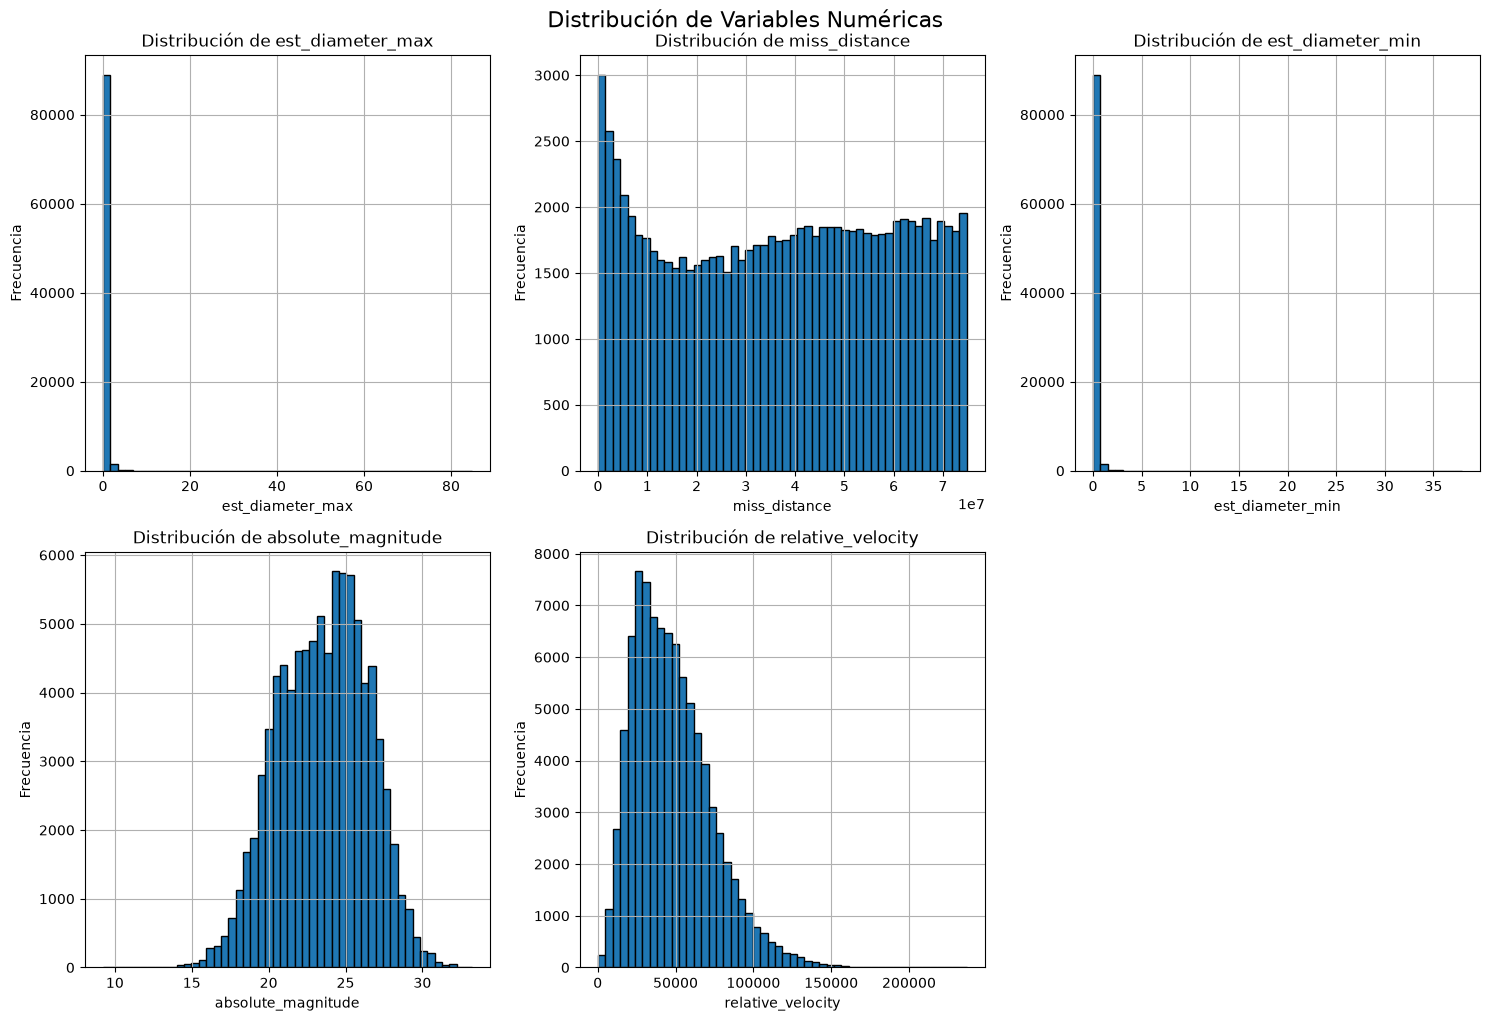

In [7]:
columnas_numericas={
"est_diameter_min",
"est_diameter_max",
"relative_velocity",
"miss_distance",
"absolute_magnitude"}
nrows=3
ncols=min(len(columnas_numericas),3)
# Crear la figura y los subplots
fig, axes = plt.subplots(nrows=nrows, ncols=ncols, figsize=(15, 5*nrows))
fig.suptitle('Distribución de Variables Numéricas', fontsize=16)

# Aplanar el array de ejes en caso de que sea 2D
axes = axes.flatten() if len(columnas_numericas) > 3 else [axes]

# Crear histogramas para cada variable numérica
for i, col in enumerate(columnas_numericas):
    ax = axes[i]
    dataset[col].hist(ax=ax, bins=50, edgecolor='black')
    ax.set_title(f'Distribución de {col}')
    ax.set_xlabel(col)
    ax.set_ylabel('Frecuencia')

# Ocultar subplots vacíos si los hay
for j in range(i+1, len(axes)):
    fig.delaxes(axes[j])

plt.tight_layout()
plt.show()


Al revisar los gráficos vemos que las variables relativas al diametro tienen una distribución que nos hace pensar que puedan haber valores atípicos, por lo tanto, vamos a hacer un análisis por separado

#### est_diameter_min



Estadísticas para O3:
Q1 - 1.5IQR = -0.17
Q1 = 0.02
Mediana = 0.05
Q3 = 0.14
Q3 + 1.5IQR = 0.33
Número de observaciones: 90836
Número de outliers: 8306


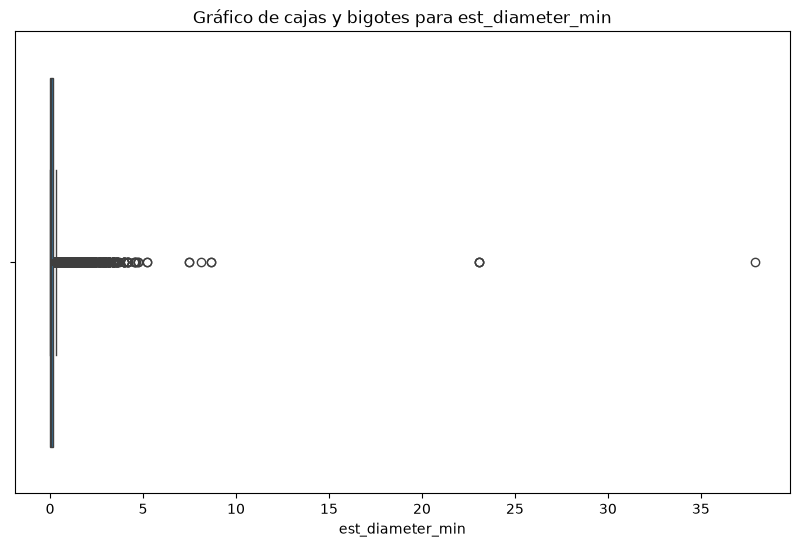

In [8]:
Q1 = dataset['est_diameter_min'].quantile(0.25)
Q3 = dataset['est_diameter_min'].quantile(0.75)
IQR = Q3 - Q1
lower_bound = Q1 - 1.5 * IQR
upper_bound = Q3 + 1.5 * IQR
print(f"Estadísticas para O3:")
print(f"Q1 - 1.5IQR = {lower_bound:.2f}")
print(f"Q1 = {Q1:.2f}")
print(f"Mediana = {dataset['est_diameter_min'].median():.2f}")
print(f"Q3 = {Q3:.2f}")
print(f"Q3 + 1.5IQR = {upper_bound:.2f}")
print(f"Número de observaciones: {len(dataset['est_diameter_min'])}")
print(f"Número de outliers: {sum((dataset['est_diameter_min'] < lower_bound) | (dataset['est_diameter_min'] > upper_bound))}")
plt.figure(figsize=(10, 6))
sns.boxplot(x=dataset['est_diameter_min'])
plt.title('Gráfico de cajas y bigotes para est_diameter_min')
plt.xlabel('est_diameter_min')
plt.show()

Los datos que arroja este análisis sobre la variable `est_diameter_min` revelan patrones interesantes. Los estadísticos descriptivos muestran una mediana de **0.05 kilómetros**, con un rango interquartílico (IQR) que va desde **-0.17 kilómetros** (Q1) a **0.14 kilómetros**

El diagrama de cajas y bigotes ilustra una *marcada presencia de valores atípicos por encima del límite superior*, identificándose específicamente 8306 observaciones que superan este umbral sobre un total de 90836 mediciones(aproximadamente un 9% de los datos)

Estadísticas para O3:
Q1 - 1.5IQR = -0.37
Q1 = 0.04
Mediana = 0.11
Q3 = 0.32
Q3 + 1.5IQR = 0.74
Número de observaciones: 90836
Número de outliers: 8306


Text(0.5, 0, 'est_diameter_max')

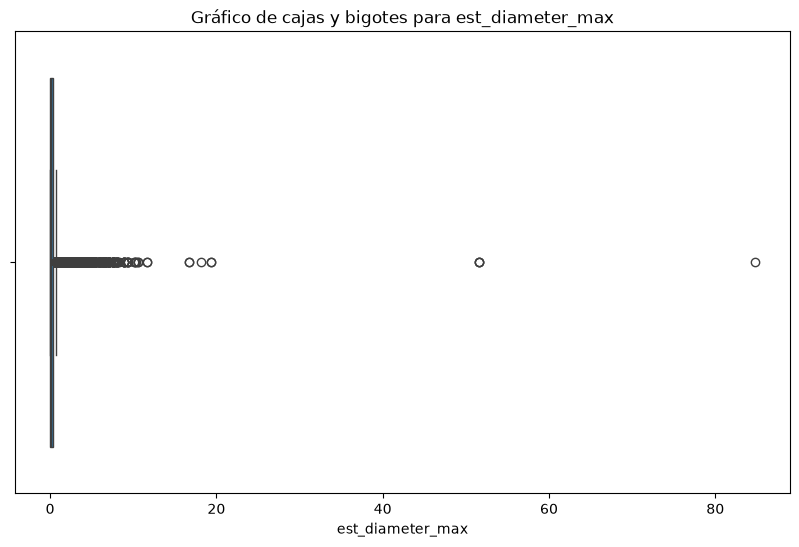

In [9]:
Q1 = dataset['est_diameter_max'].quantile(0.25)
Q3 = dataset['est_diameter_max'].quantile(0.75)
IQR = Q3 - Q1
lower_bound = Q1 - 1.5 * IQR
upper_bound = Q3 + 1.5 * IQR
print(f"Estadísticas para O3:")
print(f"Q1 - 1.5IQR = {lower_bound:.2f}")
print(f"Q1 = {Q1:.2f}")
print(f"Mediana = {dataset['est_diameter_max'].median():.2f}")
print(f"Q3 = {Q3:.2f}")
print(f"Q3 + 1.5IQR = {upper_bound:.2f}")
print(f"Número de observaciones: {len(dataset['est_diameter_max'])}")
print(f"Número de outliers: {sum((dataset['est_diameter_max'] < lower_bound) | (dataset['est_diameter_max'] > upper_bound))}")
plt.figure(figsize=(10, 6))
sns.boxplot(x=dataset['est_diameter_max'])
plt.title('Gráfico de cajas y bigotes para est_diameter_max')
plt.xlabel('est_diameter_max')

Los datos que arroja este análisis sobre la variable `est_diameter_max` revelan patrones interesantes. Los estadísticos descriptivos muestran una mediana de **0.11 kilómetros**, con un rango interquartílico (IQR) que va desde **-0.37 kilómetros** (Q1) a **0.74 kilómetros**

El diagrama de cajas y bigotes ilustra una *marcada presencia de valores atípicos por encima del límite superior*, identificándose específicamente 8306 observaciones que superan este umbral sobre un total de 90836 mediciones(aproximadamente un 9% de los datos)

In [12]:
dataset['hazardous'].value_counts(normalize=True)*100

hazardous
False    90.268176
True      9.731824
Name: proportion, dtype: float64